# **Treinamento de Modelos, Função de Custo, Overfitting, Underfitting e Separação de Dados**
##Introdução Teórica
* O modelo de Machine Learning aprende ajustando seus parâmetros para minimizar uma função de custo (ou loss function), que mede o erro entre a previsão e o valor real.

* Um exemplo comum para regressão é o Erro Quadrático Médio (MSE):
$$
MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2
$$

* Problemas comuns:

   * *Underfitting*: modelo muito simples que não captura a complexidade dos dados.

   * *Overfitting*: modelo muito complexo que decorou os dados de treino incluindo ruídos, falhando em dados novos.

* A solução prática é separar os dados para treino, validação e teste, garantindo avaliação justa e controle dos problemas do modelo.

## Atividade Prática: Regressão Linear com Separação de Dados

**Objetivo:**
Treinar um modelo simples de regressão linear em dados sintéticos, utilizando a separação correta em conjuntos de treino, validação e teste. Avaliar o erro em cada conjunto e interpretar os resultados em relação a underfitting e overfitting.

**Passos da Atividade:**

1. Gere um conjunto de dados sintético para regressão linear com ruído. Por exemplo, *y*=4+3*x*+ruído

2. Separe os dados em 3 conjuntos:
* Treino: 70%
* Validação: 15%
* Teste: 15%

3. Treine um modelo de regressão linear apenas no conjunto de treino.

4. Faça previsões nos conjuntos de treino, validação e teste.

5. Calcule o erro quadrático médio (MSE) para cada conjunto.

6. Plote os dados reais e as previsões para visualizar os ajustes do modelo.

7. Analise os valores de erro e os gráficos para discutir se o modelo está sofrendo underfitting, overfitting, ou se está bem ajustado.

**Exemplo básico de código Python:**


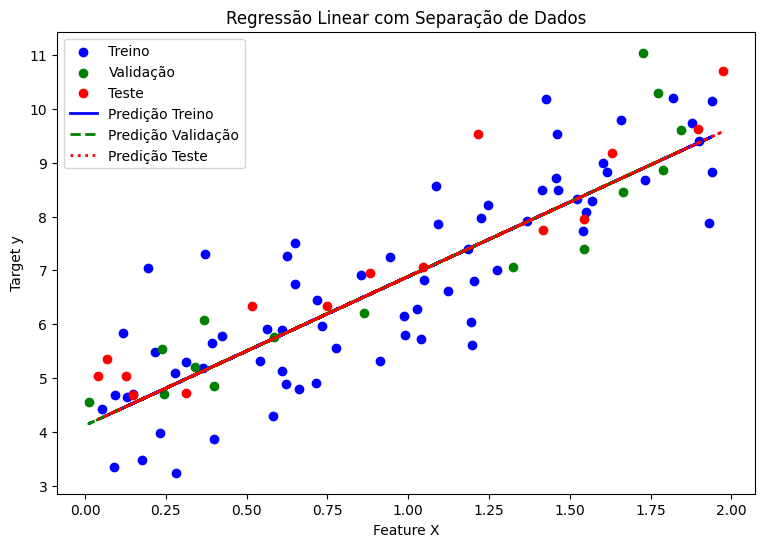

MSE Treino: 0.896
MSE Validação: 0.657
MSE Teste: 0.605


In [ ]:
# Importações necessárias
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Gerar dados sintéticos para regressão linear
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)  # y = 4 + 3x + ruído gaussiano

# Separação dos dados em treino (70%), validação (15%) e teste (15%)
# test_size=0.3
  # → Separa 30% dos dados para um conjunto temporário (X_temp)
  # → Restam 70% para treino
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
# test_size=0.5 (0.5 é aplicado sobre os 30%, não sobre o total)
  # → Divide os 30% restantes ao meio
  # → 15% validação + 15% teste
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Treinar modelo de regressão linear no conjunto de treino
model = LinearRegression()
model.fit(X_train, y_train)

# Fazer previsões nos três conjuntos
train_preds = model.predict(X_train)
val_preds = model.predict(X_val)
test_preds = model.predict(X_test)

# Calcular o Erro Quadrático Médio (MSE) para cada conjunto
mse_train = mean_squared_error(y_train, train_preds)
mse_val = mean_squared_error(y_val, val_preds)
mse_test = mean_squared_error(y_test, test_preds)

# Visualizar os dados e as previsões
plt.figure(figsize=(9,6))
plt.scatter(X_train, y_train, color='blue', label='Treino')
plt.scatter(X_val, y_val, color='green', label='Validação')
plt.scatter(X_test, y_test, color='red', label='Teste')
plt.plot(X_train, train_preds, color='blue', linewidth=2, label='Predição Treino')
plt.plot(X_val, val_preds, color='green', linestyle='--', linewidth=2, label='Predição Validação')
plt.plot(X_test, test_preds, color='red', linestyle=':', linewidth=2, label='Predição Teste')
plt.legend()
plt.xlabel('Feature X')
plt.ylabel('Target y')
plt.title('Regressão Linear com Separação de Dados')
plt.show()

# Mostrar erros para discussão
print(f'MSE Treino: {mse_train:.3f}')
print(f'MSE Validação: {mse_val:.3f}')
print(f'MSE Teste: {mse_test:.3f}')


* Por que separar os dados? O que acontece se usarmos todos para treino?

* Comparar o valor dos MSEs para entender se há overfitting ou underfitting.

* Visualizar o gráfico para interpretar o ajuste do modelo em cada conjunto.

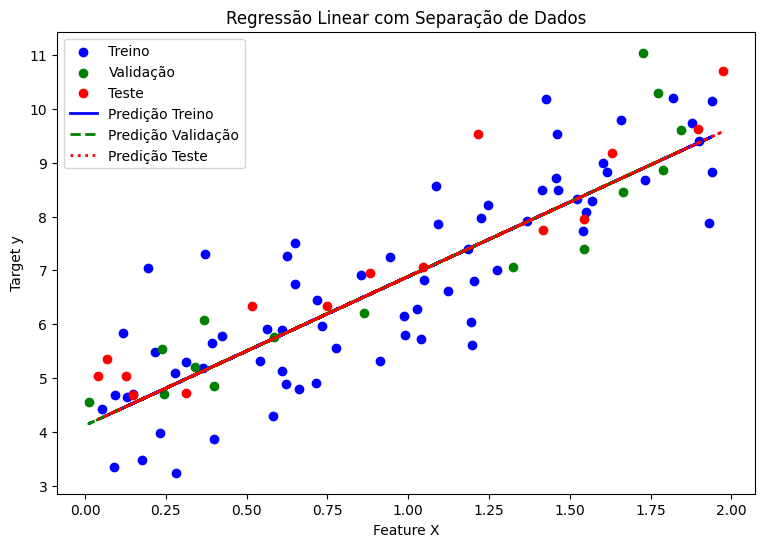

MSE Treino: 0.896
MSE Validação: 0.657
MSE Teste: 0.605


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Dados sintéticos
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

# Separação
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Modelo e treinamento
model = LinearRegression()
model.fit(X_train, y_train)

# Previsões
train_preds = model.predict(X_train)
val_preds = model.predict(X_val)
test_preds = model.predict(X_test)

# Erros
mse_train = mean_squared_error(y_train, train_preds)
mse_val = mean_squared_error(y_val, val_preds)
mse_test = mean_squared_error(y_test, test_preds)

# Plot
plt.figure(figsize=(9,6))
plt.scatter(X_train, y_train, color='blue', label='Treino')
plt.scatter(X_val, y_val, color='green', label='Validação')
plt.scatter(X_test, y_test, color='red', label='Teste')
plt.plot(X_train, train_preds, color='blue', linewidth=2, label='Predição Treino')
plt.plot(X_val, val_preds, color='green', linestyle='--', linewidth=2, label='Predição Validação')
plt.plot(X_test, test_preds, color='red', linestyle=':', linewidth=2, label='Predição Teste')
plt.legend()
plt.xlabel('Feature X')
plt.ylabel('Target y')
plt.title('Regressão Linear com Separação de Dados')
plt.show()

print(f'MSE Treino: {mse_train:.3f}')
print(f'MSE Validação: {mse_val:.3f}')
print(f'MSE Teste: {mse_test:.3f}')


> ## Atividade Prática: Previsão de Preço de Casas com Modelo de Regressão


Objetivo:
Treinar um modelo de regressão linear para prever preços de casas usando a base California Housing do scikit-learn. Aplicar separação de dados (train/val/test), avaliação de erro e visualização dos resultados.



MSE Treino: 0.52
MSE Validação: 0.54
MSE Teste: 0.52
R2 Treino: 0.61
R2 Validação: 0.58
R2 Teste: 0.61


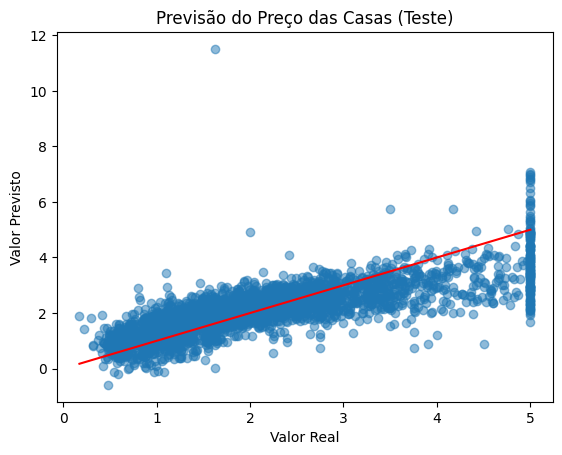

In [ ]:
# Importações necessárias
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. Carregar a base 'California Housing'
base = fetch_california_housing()
X = base.data
y = base.target

# 2. Separar em treino (70%), validação (15%), teste (15%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# 3. Treinar modelo de regressão linear
reg = LinearRegression()
reg.fit(X_train, y_train)

# 4. Fazer previsões
y_pred_train = reg.predict(X_train)
y_pred_val = reg.predict(X_val)
y_pred_test = reg.predict(X_test)

# 5. Avaliação dos erros
mse_train = mean_squared_error(y_train, y_pred_train)
mse_val = mean_squared_error(y_val, y_pred_val)
mse_test = mean_squared_error(y_test, y_pred_test)

r2_train = r2_score(y_train, y_pred_train)
r2_val = r2_score(y_val, y_pred_val)
r2_test = r2_score(y_test, y_pred_test)

print(f"MSE Treino: {mse_train:.2f}")
print(f"MSE Validação: {mse_val:.2f}")
print(f"MSE Teste: {mse_test:.2f}")
print(f"R2 Treino: {r2_train:.2f}")
print(f"R2 Validação: {r2_val:.2f}")
print(f"R2 Teste: {r2_test:.2f}")

# 6. Visualização
plt.scatter(y_test, y_pred_test, alpha=0.5)
plt.xlabel('Valor Real')
plt.ylabel('Valor Previsto')
plt.title('Previsão do Preço das Casas (Teste)')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.show()


Compare os valores de MSE e R² entre os conjuntos: há sinais de overfitting ou underfitting?

Tente substituir o modelo por outros do scikit-learn (ex: DecisionTreeRegressor, RandomForestRegressor) e veja como os resultados mudam.

Discuta a importância de cada feature para a previsão (em modelos lineares, acesso via reg.coef_).